# Official CD4+ T-cell Perturb-seq Candidate Triage

> **What this is:** a teaching walkthrough of the official hackathon-recommended dataset.
> **What this is not:** an independent reanalysis of all 22 million single cells or wet-lab
> validation of a drug target.

**Audience:** learners who know basic Python/dataframes and want to understand how a large
Perturb-seq study can be turned into a cautious, auditable target-triage result.

**Prerequisites:**

- install the project with `uv sync --extra dev`;
- internet access on the first run so the CLI can retrieve the public source tables;
- basic familiarity with rows, columns, averages, and rankings;
- no prior CRISPR or single-cell analysis experience is required.

**Learning goals:** by the end, you can explain:

- what CRISPRi, guide RNAs, non-targeting controls, donors, and culture conditions mean;
- how the source-table audit and hard-filter funnel protect the analysis;
- what the composite score does and does **not** measure;
- why cross-condition rankings are descriptive, not interaction tests;
- how donor-matched IL10/IL21 follow-up strengthens or weakens a candidate story;
- which conclusions are recomputed here and which remain source-reported.


## Outline

1. Run the reproducible command-line workflow.
2. Learn the official dataset and experimental vocabulary.
3. Audit the downloaded source tables and study design.
4. Follow candidates through the hard-filter funnel.
5. Decompose the composite priority score.
6. Read the top candidates within each condition.
7. interpret the cross-condition ranking without inventing an interaction.
8. Inspect the authors' polarization-model annotations descriptively.
9. Inspect donor-matched IL10 and IL21 follow-up.
10. Practice the limitations, pitfalls, and next experiments.

Expected time: 45-75 minutes, including exercises.


## The question and the evidence boundary

The project asks a **triage** question:

> Which perturbations pass predeclared source-quality gates and rank highly on a transparent
> combination of source-reported discovery breadth and reproducibility?

The workflow starts from the authors' public processed tables. It recomputes the audit, filters,
percentile features, geometric-mean rankings, donor-matched cytokine deltas, figures, and report.
It does not
download and refit the full cell-level model.

Two boundaries matter throughout:

1. `crossdonor_min` and `crossguide` are **source-reported reproducibility summaries**, not an
   independent recomputation from raw cells in this project.
2. `n_downstream` is the authors' count of downstream discoveries at **10% FDR**. It is
   power-dependent: more cells, lower noise, and larger effects can produce more discoveries.
   It is not a direct meter of biological importance.


In [1]:
from __future__ import annotations

from pathlib import Path
import json
import subprocess

import pandas as pd
from IPython.display import Image, Markdown, display


def find_project_root(start: Path) -> Path:
    # Work whether Jupyter started in the repository or in notebooks/.
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml from the current directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data" / "official"
OUTPUT_DIR = PROJECT_ROOT / "output" / "official"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Official data cache: {DATA_DIR}")
print(f"Analysis output: {OUTPUT_DIR}")


Project root: C:\Users\miqba\projects\claude-science-hackathon-learning-plan
Official data cache: C:\Users\miqba\projects\claude-science-hackathon-learning-plan\data\official
Analysis output: C:\Users\miqba\projects\claude-science-hackathon-learning-plan\output\official


## Step 1 - Run the complete official-data workflow

The next cell runs the same CLI a reviewer can run from a terminal. `cwd=PROJECT_ROOT` makes the
relative input and output paths unambiguous. The command downloads/caches the manageable public
source tables, validates them, performs the triage, and writes tables, figures, prose, and
provenance.

The command is intentionally explicit:

```text
uv run perturbseq-triage all --data-dir data/official --output-dir output/official
```


In [2]:
command = [
    "uv",
    "run",
    "perturbseq-triage",
    "all",
    "--data-dir",
    "data/official",
    "--output-dir",
    "output/official",
]

completed = subprocess.run(
    command,
    cwd=PROJECT_ROOT,
    check=False,
    text=True,
    capture_output=True,
)
print(completed.stdout[-4_000:])
if completed.stderr:
    print("Diagnostic output:")
    print(completed.stderr[-2_000:])
completed.check_returncode()


{
  "status": "complete",
  "source_qc_passes_by_condition": {
    "Rest": 497,
    "Stim8hr": 593,
    "Stim48hr": 562
  },
  "cross_condition_candidate_count": 224,
  "lead_cross_condition_candidate": {
    "gene": "SETDB1",
    "min_priority_score": 0.9146892514429616,
    "worst_condition": "Stim8hr"
  },
  "output_dir": "C:\\Users\\miqba\\projects\\claude-science-hackathon-learning-plan\\output\\official",
  "manifest": "C:\\Users\\miqba\\projects\\claude-science-hackathon-learning-plan\\output\\official\\provenance\\manifest.json"
}



### Confirm the analysis contract

A successful process exit is useful, but expected artifacts make the contract concrete. This
cell fails early if a partial run omitted a required table, figure, or provenance record.


In [3]:
expected_artifacts = [
    "provenance/source_audit.json",
    "provenance/manifest.json",
    "tables/source_qc_decisions.csv",
    "tables/filter_funnel.csv",
    "tables/candidate_scores.csv",
    "tables/top_candidates_by_condition.csv",
    "tables/cross_condition_candidates.csv",
    "tables/validation_donor_deltas.csv",
    "tables/validation_summary.csv",
    "tables/sample_design_summary.csv",
    "tables/candidate_polarization_coefficients.csv",
    "figures/01_filter_funnel.png",
    "figures/02_top_candidates.png",
    "figures/03_cross_condition_scores.png",
    "figures/04_arrayed_validation_deltas.png",
    "report.md",
    "methods.md",
]
artifact_check = pd.DataFrame(
    {
        "artifact": expected_artifacts,
        "exists": [(OUTPUT_DIR / name).is_file() for name in expected_artifacts],
    }
)
display(artifact_check)
assert artifact_check["exists"].all(), "The official run is incomplete; inspect the CLI output."


,artifact,exists
0,provenance/source_audit.json,True
1,provenance/manifest.json,True
2,tables/source_qc_decisions.csv,True
3,tables/filter_funnel.csv,True
4,tables/candidate_scores.csv,True
5,tables/top_candidates_by_condition.csv,True
6,tables/cross_condition_candidates.csv,True
7,tables/validation_donor_deltas.csv,True
8,tables/validation_summary.csv,True
9,tables/sample_design_summary.csv,True


## Step 2 - Understand the official experiment

The recommended dataset is the
[Primary Human CD4+ T Cell Perturb-seq dataset][official-dataset].
It contains roughly 22 million cells from four donors under three culture conditions: `Rest`,
`Stim8hr`, and `Stim48hr`. The study used genome-scale CRISPR interference in primary human CD4+
T cells. This is the T-cell dataset linked by the
[Built with Claude: Life Sciences event][hackathon-event].

| Term | Plain-language meaning | Why it matters here |
|---|---|---|
| CRISPRi | A guide brings a repression system to a gene to reduce its expression. | It creates a directional intervention, but knockdown can be incomplete. |
| Guide RNA | The sequence that points CRISPRi toward a target gene. | Multiple guides can check whether an effect repeats for the same target. |
| NTC | A non-targeting control guide with no intended human-gene target. | It estimates the background state for comparison. |
| Donor | One person who supplied primary cells. | Donors are biological replicates; cells from one donor are not new people. |
| Condition | Resting, 8-hour stimulation, or 48-hour stimulation context. | A perturbation can behave differently as the cell state changes. |
| On-target effect | Evidence that the intended target was actually knocked down. | A weak intervention makes downstream interpretation less credible. |
| Downstream discovery | Another gene reported as responding to the perturbation. | Breadth can be useful, but is strongly affected by statistical power. |

The project deliberately uses the study's compact supplementary outputs rather than requiring a
learner to download the full cell-level collection. See the authors'
[data-sharing README][sharing-readme]
for the full file inventory.

[official-dataset]: https://virtualcellmodels.cziscience.com/dataset/genome-scale-tcell-perturb-seq
[sharing-readme]: https://github.com/emdann/GWT_perturbseq_analysis_2025/blob/master/metadata/data_sharing_readme.md
[hackathon-event]: https://cerebralvalley.ai/e/built-with-claude-life-sciences


## Step 3 - Audit the source before scoring anything

An audit should answer: Which files were used? Did the checksums match? Are required columns and
conditions present? How many records were read? A ranking is not reproducible if its inputs are
ambiguous.


In [4]:
source_audit = json.loads(
    (OUTPUT_DIR / "provenance" / "source_audit.json").read_text(encoding="utf-8")
)
audit_view = pd.json_normalize(source_audit, sep=".").T
audit_view.columns = ["recorded value"]
display(audit_view)


,recorded value
status,passed
checks.all_validation_donors_have_ntc,True
checks.boolean_columns_parse,True
checks.numeric_columns_parse,True
checks.unique_gene_condition_rows,True
checks.unique_sample_ids,True
design.arrayed_validation_donors,"[Donor10, Donor5, Donor6, Donor7, Donor8, Donor9]"
design.conditions,"[Rest, Stim8hr, Stim48hr]"
design.screen_donors,"[CE0006864, CE0008162, CE0008678, CE0010866]"
design.screen_samples,12


### Inspect the experimental design represented in the source tables

The design summary prevents a common category error: a large number of rows or cells does not
imply a large number of independent donors. Read it before interpreting a score.


In [5]:
design = pd.read_csv(TABLE_DIR / "sample_design_summary.csv")
display(design)


,culture_condition,n_samples,n_donors,n_runs,n_libraries
0,Rest,4,4,2,4
1,Stim8hr,4,4,2,4
2,Stim48hr,4,4,1,4


### Inspect each source row and its gate decisions

`source_qc_decisions.csv` is the human-auditable ledger. It retains failed rows, the boolean
decision for every hard gate, the final `source_qc_pass`, and a readable failure reason. That is
safer than silently deleting records before anyone can inspect them.

The predeclared gates are:

| Gate | Passing rule |
|---|---|
| On-target significance | `ontarget_significant == True` |
| On-target direction | `ontarget_effect_size < 0` (the target was reduced) |
| Off-target flag | `offtarget_flag == False` |
| Target-cell support | `n_cells_target >= 100` |
| Cross-donor summary | `crossdonor_min` is present and greater than 0 |
| Cross-guide summary | `crossguide` is present and greater than 0 |


In [6]:
source_qc = pd.read_csv(TABLE_DIR / "source_qc_decisions.csv")
gate_columns = [
    column
    for column in source_qc.columns
    if (
        (column.endswith("_pass") or column.startswith("gate_"))
        and column != "source_qc_pass"
    )
]
summary_columns = [
    "gene",
    "culture_condition",
    "n_cells_target",
    "n_downstream",
    "ontarget_effect_size",
    "ontarget_significant",
    "offtarget_flag",
    "crossdonor_min",
    "crossguide",
    *gate_columns,
    "source_qc_pass",
    "qc_failure_reasons",
]
display(source_qc[summary_columns].head(12))
display(source_qc["source_qc_pass"].value_counts(dropna=False).rename("rows").to_frame())


,gene,culture_condition,n_cells_target,n_downstream,ontarget_effect_size,ontarget_significant,offtarget_flag,crossdonor_min,crossguide,gate_ontarget_significant,gate_negative_ontarget_effect,gate_no_offtarget_flag,gate_min_cells,gate_crossdonor_present,gate_crossdonor_positive,gate_crossguide_present,gate_crossguide_positive,source_qc_pass,qc_failure_reasons
0,A1BG,Rest,734,1,0.000000,False,False,NaN,NaN,False,False,True,True,False,False,False,False,False,on_target_not_significant;on_target_effect_not...
1,A2M,Rest,366,122,0.000000,False,False,-0.424675,-0.466086,False,False,True,True,True,False,True,False,False,on_target_not_significant;on_target_effect_not...
2,AAAS,Rest,677,0,-2.724938,False,False,NaN,NaN,False,True,True,True,False,False,False,False,False,on_target_not_significant;cross_donor_metric_m...
3,AACS,Rest,724,4,-10.164948,True,False,NaN,NaN,True,True,True,True,False,False,False,False,False,cross_donor_metric_missing;cross_donor_metric_...
4,AAGAB,Rest,647,2,-18.512724,True,False,NaN,NaN,True,True,True,True,False,False,False,False,False,cross_donor_metric_missing;cross_donor_metric_...
5,AAK1,Rest,1244,2,-28.668717,True,False,NaN,NaN,True,True,True,True,False,False,False,False,False,cross_donor_metric_missing;cross_donor_metric_...
6,AAMDC,Rest,376,1,-4.527614,True,True,NaN,NaN,True,True,False,True,False,False,False,False,False,off_target_flagged;cross_donor_metric_missing;...
7,AAR2,Rest,62,36,-0.639841,True,False,-0.234213,NaN,True,True,True,False,True,False,False,False,False,fewer_than_100_target_cells;cross_donor_metric...
8,AARS2,Rest,132,0,0.000000,False,False,NaN,NaN,False,False,True,True,False,False,False,False,False,on_target_not_significant;on_target_effect_not...
9,AARSD1,Rest,771,0,-1.201313,False,False,NaN,NaN,False,True,True,True,False,False,False,False,False,on_target_not_significant;cross_donor_metric_m...


,rows
source_qc_pass,
False,32331
True,1652


## Step 4 - Follow the hard-filter funnel

Hard gates answer **eligibility**, not priority. They remove rows that do not meet the declared
minimum evidence requirements before any geometric-mean score is calculated. The funnel makes the
cost of each gate visible by condition; a sudden condition-specific collapse should trigger an
audit, not a celebratory top-hit list.


In [7]:
funnel = pd.read_csv(TABLE_DIR / "filter_funnel.csv")
funnel = funnel.sort_values(["culture_condition", "stage_order"])
display(
    funnel.pivot(
        index=["stage_order", "stage"],
        columns="culture_condition",
        values="n_rows",
    )
)


,culture_condition,Rest,Stim48hr,Stim8hr
stage_order,stage,,,
0,all_screen_rows,11287,11281,11415
1,on_target_significant,6869,7193,7154
2,negative_on_target_effect,6869,7193,7153
3,off_target_flag_false,6063,6410,6289
4,n_cells_target_at_least_100,5905,6230,6103
5,cross_donor_metric_present_and_positive,806,873,859
6,cross_guide_metric_present_and_positive,497,562,593


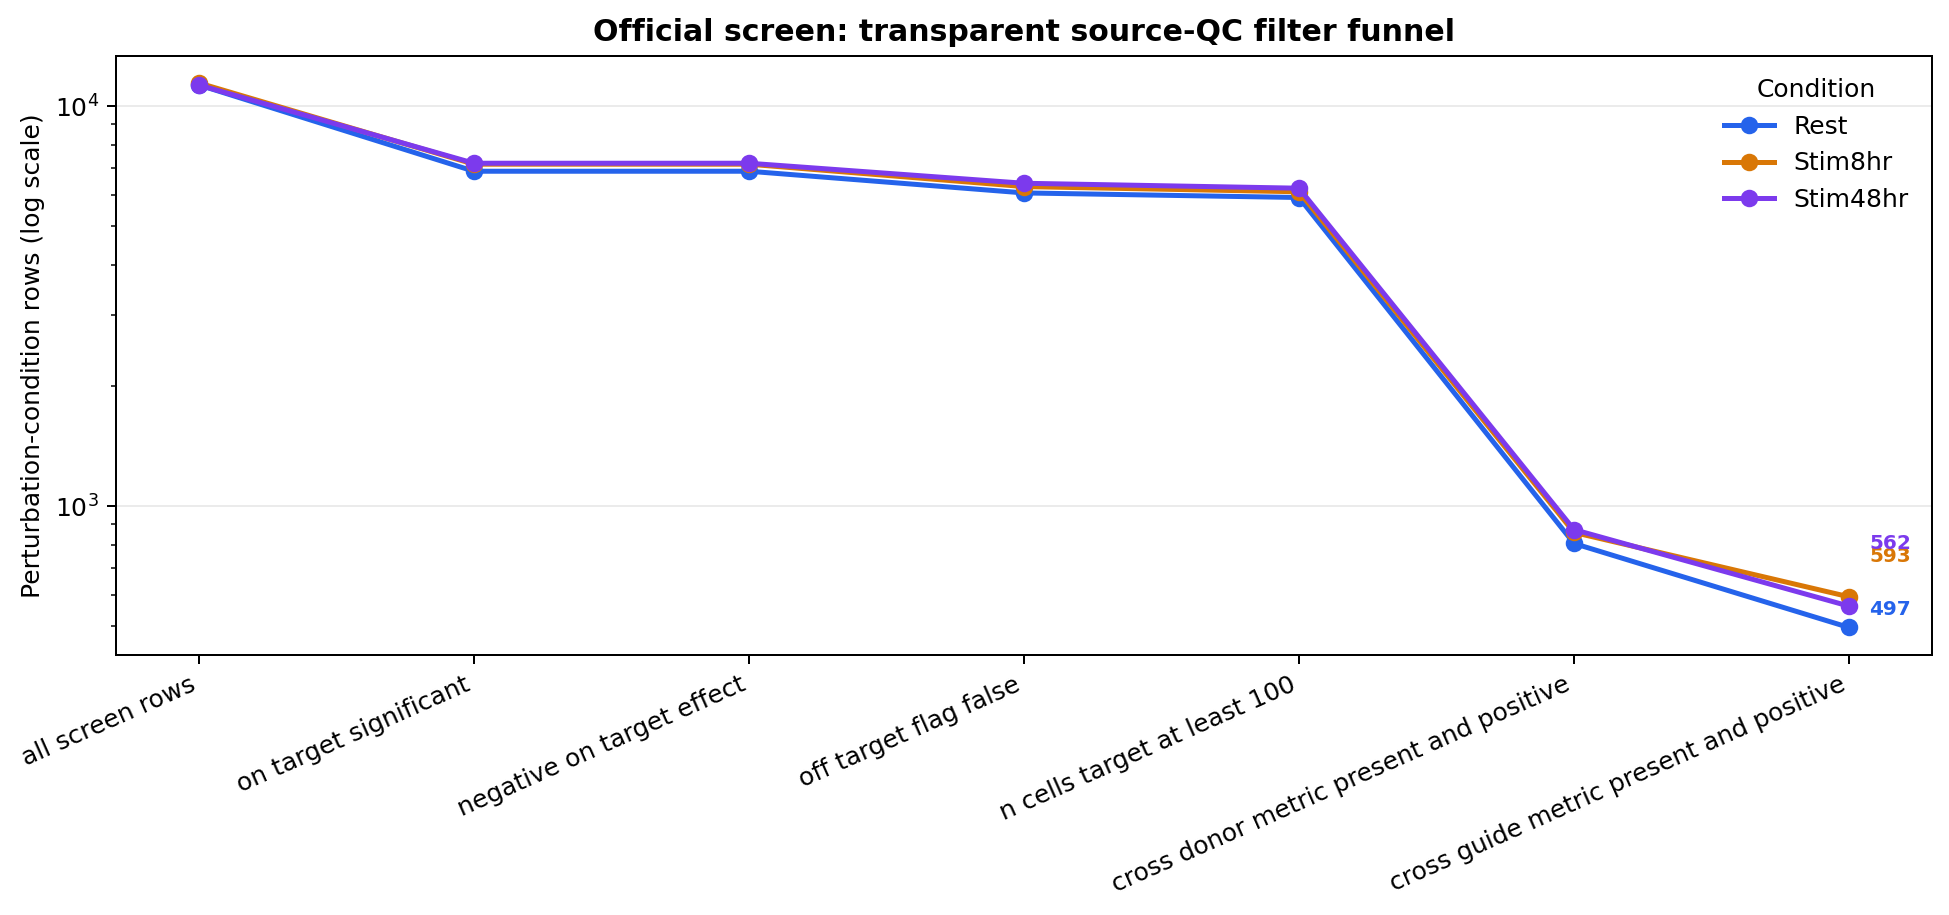

In [8]:
display(Image(filename=FIGURE_DIR / "01_filter_funnel.png", width=1000))


### Exercise 1 - Find the most restrictive gate

For each condition, calculate the number and fraction of rows lost at every step. Which step is
most restrictive? Then inspect a few rows with that failure reason before deciding whether the
threshold is scientifically sensible.


In [9]:
# Answer scaffold: keep the first stage as the denominator for an intuitive loss fraction.
exercise_1 = funnel.copy()
exercise_1["rows_lost_at_stage"] = -exercise_1.groupby("culture_condition")["n_rows"].diff()
exercise_1["starting_rows"] = exercise_1.groupby("culture_condition")["n_rows"].transform("first")
exercise_1["fraction_of_start_lost"] = (
    exercise_1["rows_lost_at_stage"] / exercise_1["starting_rows"]
)
exercise_1.sort_values(
    ["culture_condition", "rows_lost_at_stage"], ascending=[True, False]
).head(9)


,culture_condition,stage_order,stage,n_rows,rows_lost_at_stage,starting_rows,fraction_of_start_lost
5,Rest,5,cross_donor_metric_present_and_positive,806,5099.0,11287,0.451759
1,Rest,1,on_target_significant,6869,4418.0,11287,0.391424
3,Rest,3,off_target_flag_false,6063,806.0,11287,0.071410
6,Rest,6,cross_guide_metric_present_and_positive,497,309.0,11287,0.027377
4,Rest,4,n_cells_target_at_least_100,5905,158.0,11287,0.013998
2,Rest,2,negative_on_target_effect,6869,-0.0,11287,-0.000000
0,Rest,0,all_screen_rows,11287,NaN,11287,NaN
19,Stim48hr,5,cross_donor_metric_present_and_positive,873,5357.0,11281,0.474869
15,Stim48hr,1,on_target_significant,7193,4088.0,11281,0.362379


## Step 5 - Read the composite priority score

Only rows that pass every hard gate receive a priority score. The workflow first converts each
component to a within-condition percentile so measurements with different units can be combined.
Higher percentiles always mean stronger evidence. Within each condition, pandas average ranks are
converted to percentiles with `rank(method="average", pct=True)`. The priority score is the
geometric mean of three ranks: `n_downstream_percentile`, `crossdonor_min_percentile`, and
`crossguide_percentile`.
A geometric mean rewards candidates that are jointly strong and penalizes a weak component. It
is a transparent ranking heuristic, not a probability of success and not a p-value.

Keep the evidence boundary visible:

- `crossdonor_min` and `crossguide` are the authors' reported reproducibility summaries. This
  workflow uses them; it does not independently refit them from the 22 million cells.
- `n_downstream` counts the authors' discoveries at 10% FDR. Because discovery counts depend on
  power, it should never dominate the score or be described as pure biological breadth.
- Ties and percentile choices can still affect ranks. The component columns remain available so
  a reviewer can audit the score directly.


In [10]:
scores = pd.read_csv(TABLE_DIR / "candidate_scores.csv")
percentile_columns = [
    "n_downstream_percentile",
    "crossdonor_min_percentile",
    "crossguide_percentile",
]
assert set(percentile_columns).issubset(scores.columns)
score_view = [
    "gene",
    "culture_condition",
    *percentile_columns,
    "priority_score",
    "candidate_label",
]
display(scores[score_view].sort_values("priority_score", ascending=False).head(15))


,gene,culture_condition,n_downstream_percentile,crossdonor_min_percentile,crossguide_percentile,priority_score,candidate_label
0,SETDB1,Rest,0.969819,0.951710,0.913481,0.944710,source-QC pass
1090,ARNT,Stim48hr,0.987544,0.966192,0.877224,0.942418,source-QC pass
1,PTEN,Rest,0.983903,0.961771,0.832998,0.923753,source-QC pass
1091,TADA2B,Stim48hr,1.000000,0.911032,0.857651,0.921046,source-QC pass
1092,SETDB1,Stim48hr,0.862100,0.980427,0.911032,0.916577,source-QC pass
497,ARNT,Stim8hr,0.966273,0.922428,0.861720,0.915798,source-QC pass
498,SETDB1,Stim8hr,0.873524,0.974705,0.898820,0.914689,source-QC pass
1093,KDM1A,Stim48hr,0.985765,0.967972,0.797153,0.912836,source-QC pass
2,ARNT,Rest,0.971831,0.959759,0.812877,0.911855,source-QC pass
3,PAXIP1,Rest,0.869215,0.963783,0.899396,0.909954,source-QC pass


### Exercise 2 - Audit one candidate's score

Choose one row, identify its strongest and weakest percentile components, and recompute the
geometric mean. Explain why one very low component pulls down the score even when another
component is near the top of its condition.


In [11]:
# Answer scaffold: replace the first row with a candidate you want to audit.
candidate = scores.sort_values("priority_score", ascending=False).iloc[0]
components = candidate[percentile_columns].astype(float).sort_values(ascending=False)
recomputed_score = float(components.product() ** (1 / len(components)))
exercise_2 = {
    "gene": candidate["gene"],
    "condition": candidate["culture_condition"],
    "strongest_component": components.index[0],
    "weakest_component": components.index[-1],
    "reported_priority_score": float(candidate["priority_score"]),
    "recomputed_geometric_mean": recomputed_score,
    "why_the_weakest_component_matters": "TODO: explain in your own words",
}
exercise_2


{'gene': 'SETDB1',
 'condition': 'Rest',
 'strongest_component': 'n_downstream_percentile',
 'weakest_component': 'crossguide_percentile',
 'reported_priority_score': 0.9447095128,
 'recomputed_geometric_mean': 0.9447095128475068,
 'why_the_weakest_component_matters': 'TODO: explain in your own words'}

## Step 6 - Read top candidates within each condition

Within-condition ranks are the primary output because resting, early-stimulated, and late-
stimulated cells are different biological contexts. Look across the component columns before
repeating the overall score: two candidates can tie for very different reasons.


In [12]:
top = pd.read_csv(TABLE_DIR / "top_candidates_by_condition.csv")
top_columns = [
    "culture_condition",
    "rank_within_condition",
    "gene",
    "priority_score",
    "candidate_label",
    *[column for column in percentile_columns if column in top.columns],
]
display(top[top_columns].sort_values(["culture_condition", "rank_within_condition"]))


,culture_condition,rank_within_condition,gene,priority_score,candidate_label,n_downstream_percentile,crossdonor_min_percentile,crossguide_percentile
0,Rest,1,SETDB1,0.944710,source-QC pass,0.969819,0.951710,0.913481
1,Rest,2,PTEN,0.923753,source-QC pass,0.983903,0.961771,0.832998
2,Rest,3,ARNT,0.911855,source-QC pass,0.971831,0.959759,0.812877
3,Rest,4,PAXIP1,0.909954,source-QC pass,0.869215,0.963783,0.899396
4,Rest,5,EHMT2,0.895760,source-QC pass,0.921529,0.929577,0.839034
5,Rest,6,NFRKB,0.889739,source-QC pass,0.991952,0.933602,0.760563
6,Rest,7,THRAP3,0.889390,source-QC pass,0.892354,0.839034,0.939638
7,Rest,8,AHR,0.887119,source-QC pass,0.977867,0.830986,0.859155
8,Rest,9,MED12,0.872595,source-QC pass,0.981891,0.931590,0.726358
9,Rest,10,TAF13,0.865597,source-QC pass,0.967807,0.841046,0.796781


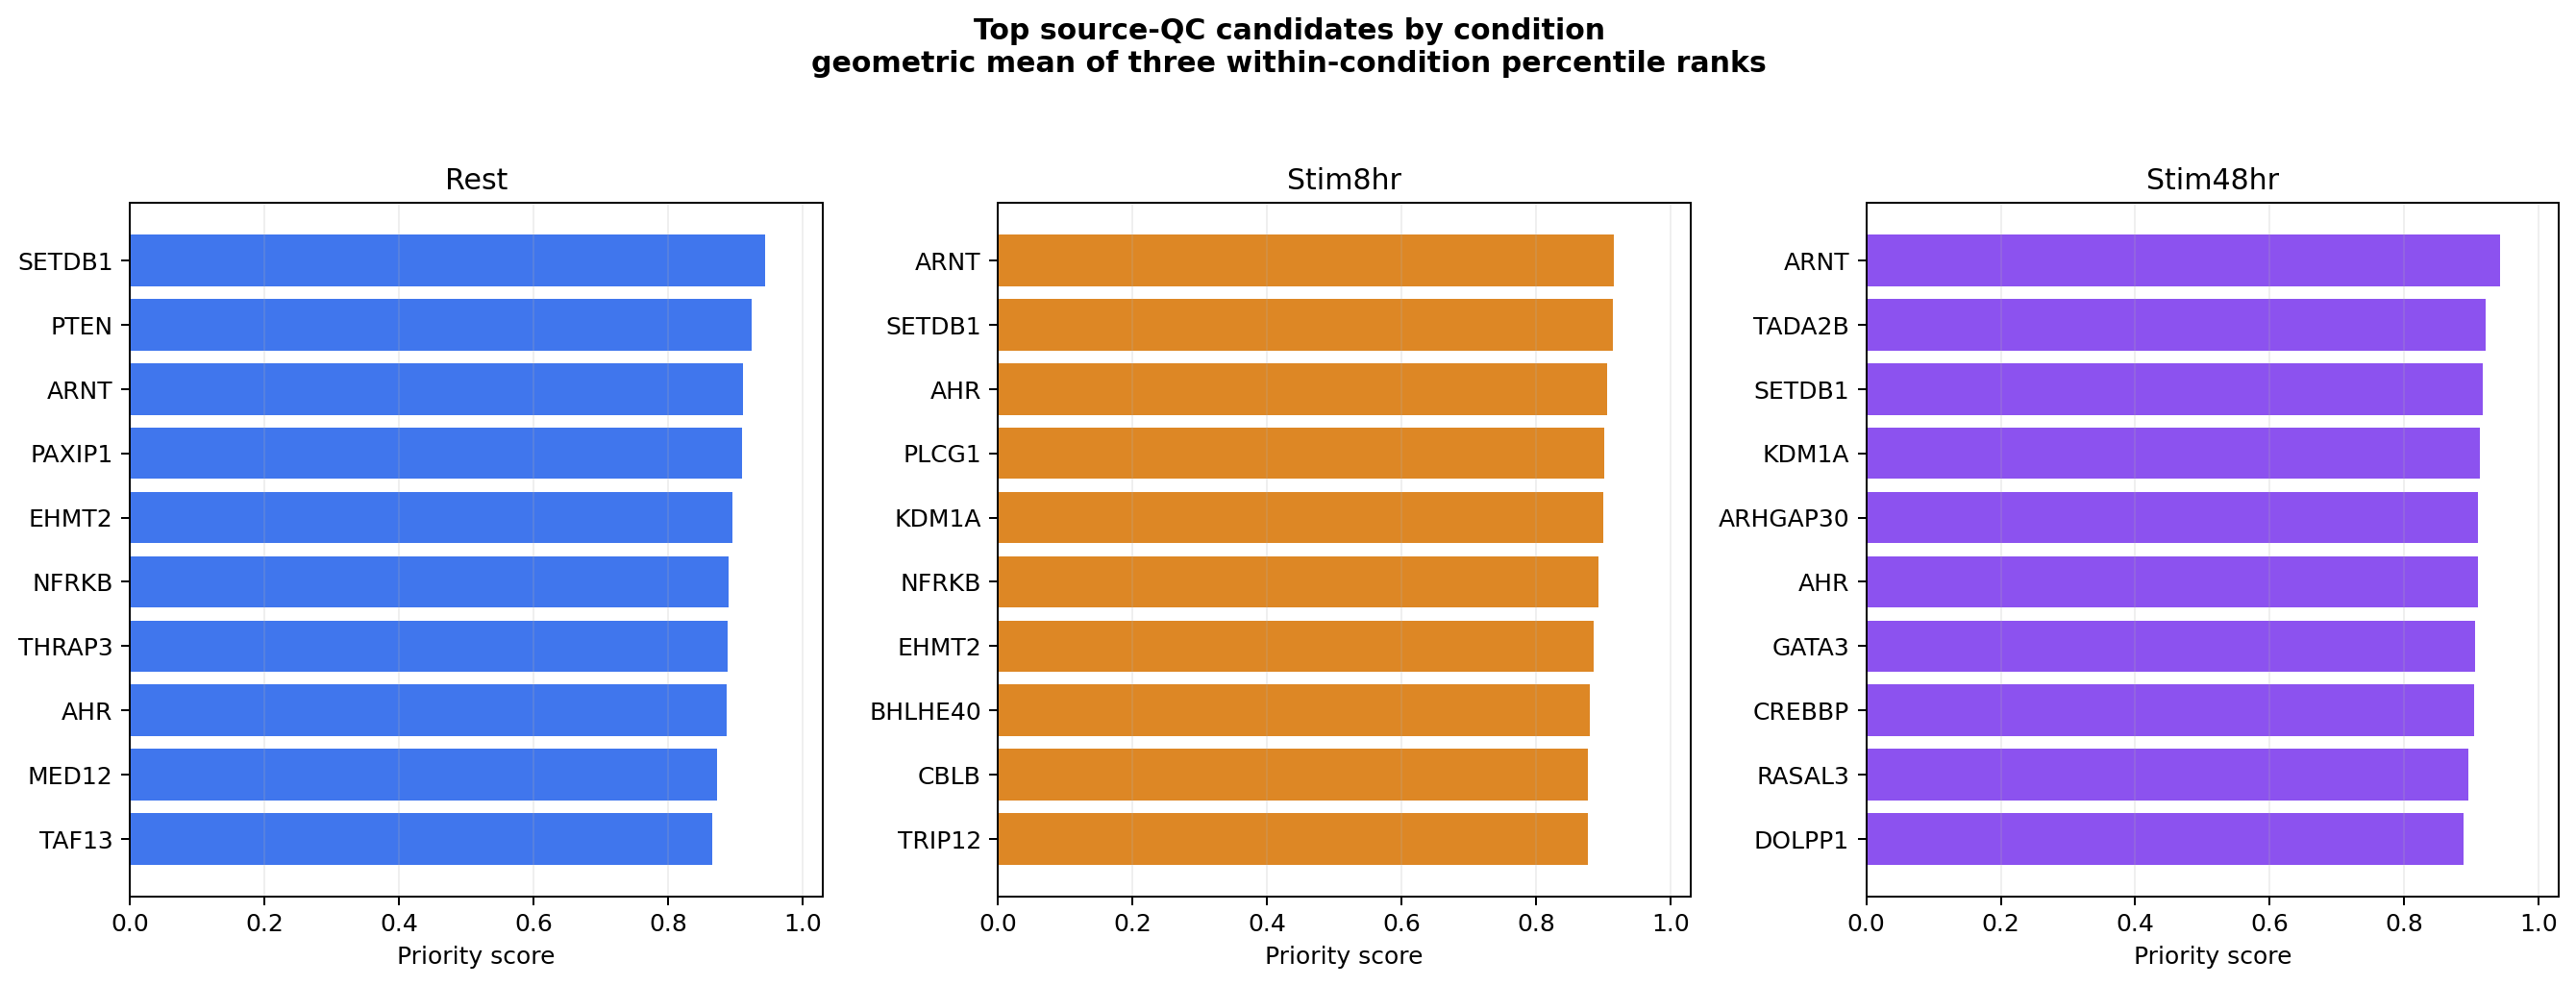

In [13]:
display(Image(filename=FIGURE_DIR / "02_top_candidates.png", width=1050))


## Step 7 - Interpret the cross-condition table descriptively

The cross-condition table includes only genes that passed in all three conditions. It ranks them
by `min_priority_score`, the weakest of their three **separately calculated** scores.
`mean_priority_score` is a secondary descriptive summary. This is useful for triage, but it is
not a model of a gene-by-condition interaction and does not quantify uncertainty in score
differences.


In [14]:
cross_condition = pd.read_csv(TABLE_DIR / "cross_condition_candidates.csv")
condition_score_columns = [
    "Rest_priority_score",
    "Stim8hr_priority_score",
    "Stim48hr_priority_score",
]
cross_columns = [
    "cross_condition_rank",
    "gene",
    *condition_score_columns,
    "min_priority_score",
    "mean_priority_score",
    "worst_condition",
    "candidate_label",
]
display(cross_condition[cross_columns].sort_values("cross_condition_rank").head(15))


,cross_condition_rank,gene,Rest_priority_score,Stim8hr_priority_score,Stim48hr_priority_score,min_priority_score,mean_priority_score,worst_condition,candidate_label
0,1,SETDB1,0.944710,0.914689,0.916577,0.914689,0.925325,Stim8hr,reproducible candidate
1,2,ARNT,0.911855,0.915798,0.942418,0.911855,0.923357,Rest,reproducible candidate
2,3,AHR,0.887119,0.905467,0.909289,0.887119,0.900625,Rest,reproducible candidate
3,4,NFRKB,0.889739,0.893207,0.884501,0.884501,0.889149,Stim48hr,reproducible candidate
4,5,EHMT2,0.895760,0.884985,0.861686,0.861686,0.880810,Stim48hr,reproducible candidate
5,6,KDM1A,0.851361,0.899507,0.912836,0.851361,0.887901,Rest,reproducible candidate
6,7,GATA3,0.840897,0.839572,0.905778,0.839572,0.862082,Stim8hr,reproducible candidate
7,8,TFAM,0.826303,0.863562,0.883053,0.826303,0.857639,Rest,reproducible candidate
8,9,TAF13,0.865597,0.846008,0.822757,0.822757,0.844787,Stim48hr,reproducible candidate
9,10,PAXIP1,0.909954,0.832696,0.821887,0.821887,0.854846,Stim48hr,reproducible candidate


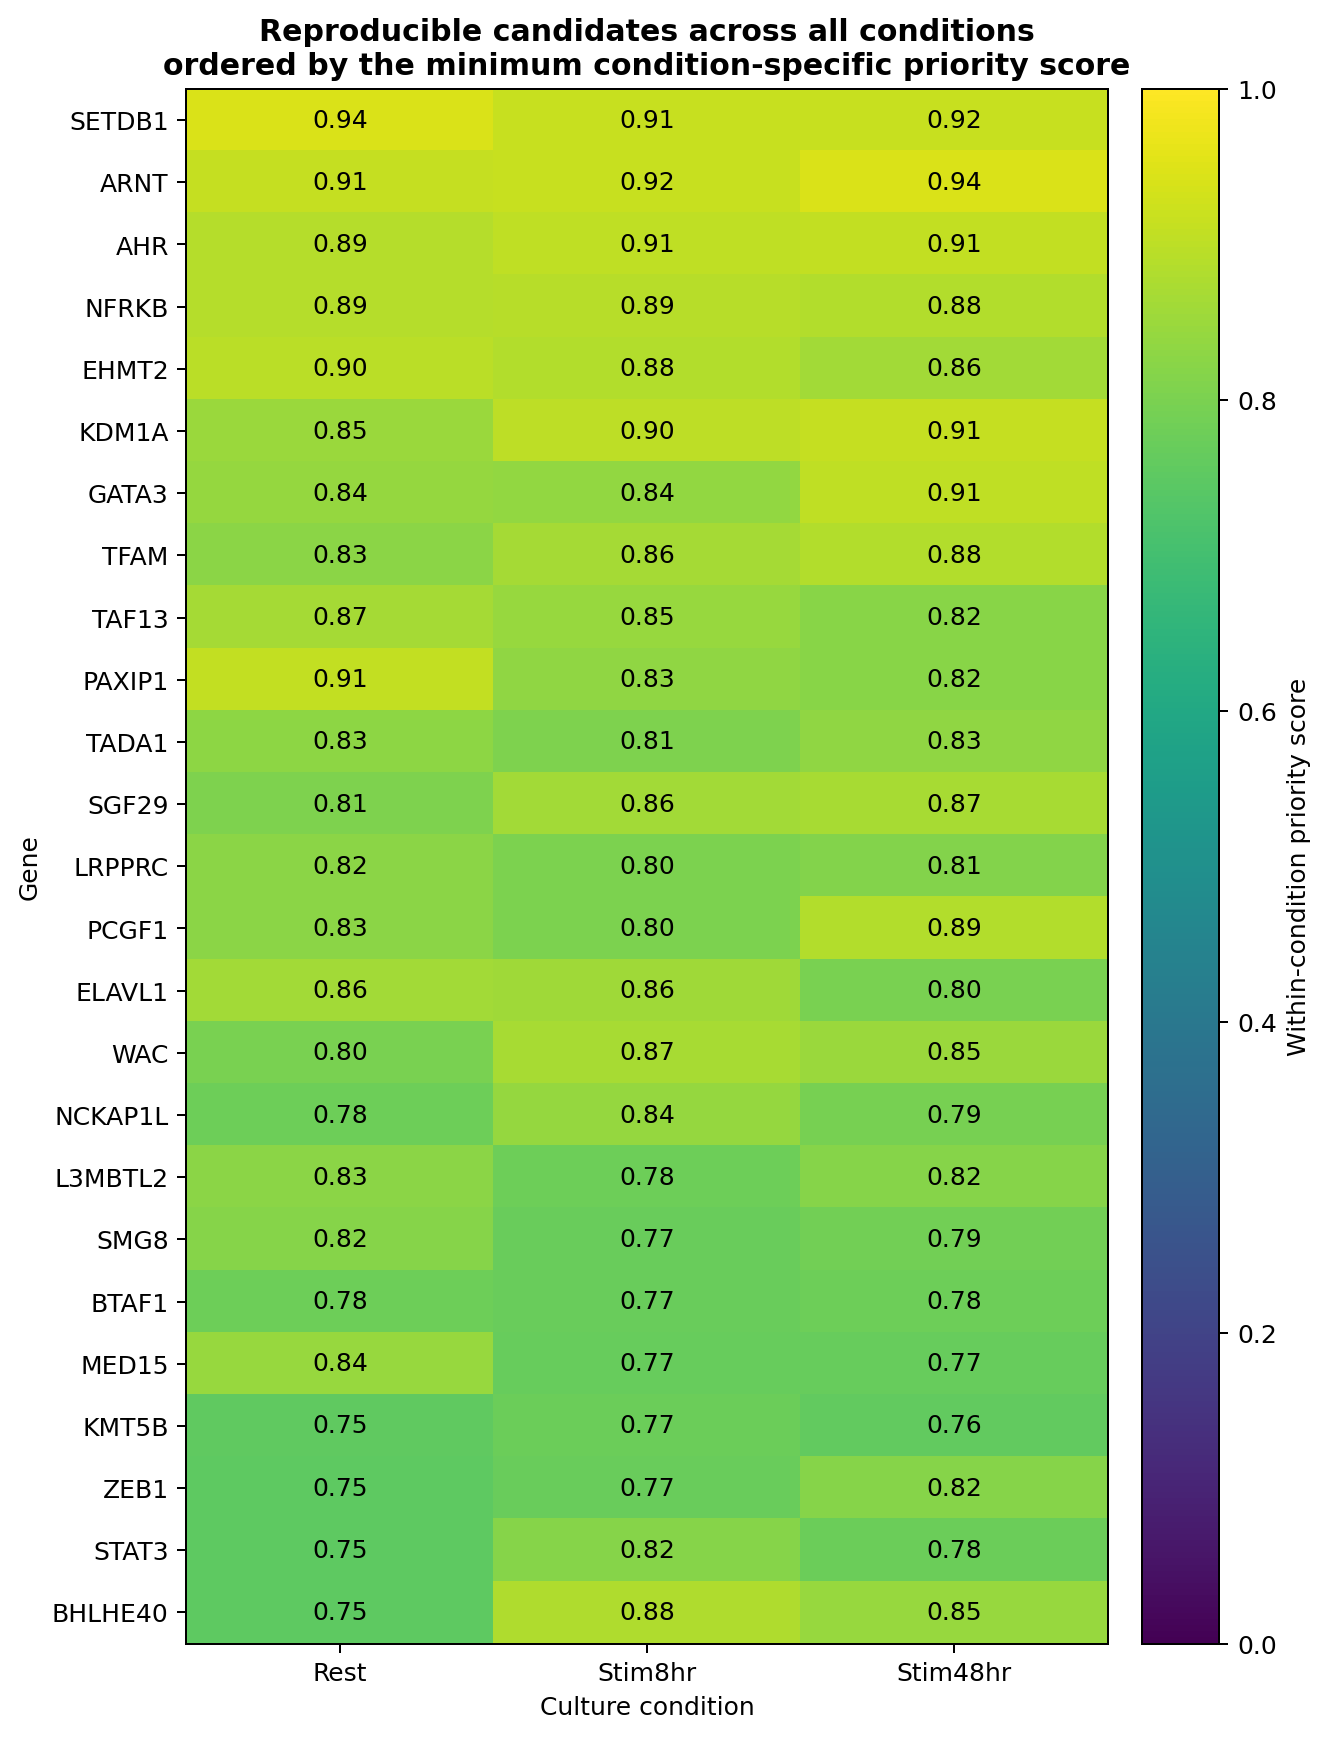

In [15]:
display(Image(filename=FIGURE_DIR / "03_cross_condition_scores.png", width=1000))


### Exercise 3 - Significant here, not significant there

Suppose a perturbation is significant in `Stim8hr` but not significant in `Stim48hr`. Can you
conclude that its biological effect differs between the two conditions? What analysis would be
needed?

Write your answer before running the scaffold.


In [16]:
exercise_3 = {
    "conclusion": (
        "No. A significant result and a non-significant result do not themselves establish "
        "a significant difference between conditions."
    ),
    "needed_analysis": (
        "Test the perturbation-by-condition interaction, or an equivalent prespecified contrast "
        "of effect estimates, with uncertainty and multiplicity correction."
    ),
    "why": (
        "The estimates can be similar while their standard errors or statistical power differ."
    ),
}
exercise_3


{'conclusion': 'No. A significant result and a non-significant result do not themselves establish a significant difference between conditions.',
 'needed_analysis': 'Test the perturbation-by-condition interaction, or an equivalent prespecified contrast of effect estimates, with uncertainty and multiplicity correction.',
 'why': 'The estimates can be similar while their standard errors or statistical power differ.'}

## Step 8 - Descriptive polarization-model annotation

The fourth source table contains the authors' regulator coefficients for polarization signatures.
The workflow filters that table to source-QC-pass genes and adds two membership flags. These
coefficients are **official descriptive annotations** from the same study: this project does not
refit the model, and their agreement with a candidate rank is not independent validation. They
are not inputs to `priority_score`.


In [17]:
polarization = pd.read_csv(TABLE_DIR / "candidate_polarization_coefficients.csv")
polarization_columns = [
    "regulator",
    "dataset_key",
    "signature",
    "coef_mean",
    "coef_sem",
    "coef_rank",
    "in_top_candidates_by_condition",
    "in_cross_condition_candidates",
]
display(polarization[polarization_columns].head(20))


,regulator,dataset_key,signature,coef_mean,coef_sem,coef_rank,in_top_candidates_by_condition,in_cross_condition_candidates
0,GATA3,ota_Rest,ota,-0.056351,0.000672,0.999739,True,True
1,SETDB1,ota_Stim48hr,ota,-0.036874,0.002012,0.998691,True,True
2,USP22,ota_Stim48hr,ota,-0.035273,0.001218,0.998429,True,True
3,WAC,activation_Stim8hr,activation,-0.046130,0.001566,0.998217,True,True
4,PTEN,ota_Stim48hr,ota,-0.033252,0.001099,0.997120,True,True
5,GATA3,ota_Stim8hr,ota,-0.029827,0.000945,0.996179,True,True
6,PTEN,activation_Rest,activation,-0.029179,0.000625,0.995309,True,True
7,EHMT2,activation_Stim48hr,activation,-0.041072,0.001026,0.995026,True,True
8,USP22,ota_Stim8hr,ota,-0.025289,0.001282,0.993123,True,True
9,KDM1A,activation_Stim48hr,activation,-0.037751,0.001026,0.992408,True,True


## Step 9 - Donor-matched IL10 and IL21 follow-up

The arrayed follow-up is a separate, smaller evidence layer. The source columns are percentages
for IL10 and IL21. For each donor and perturbation, the workflow subtracts the matched
non-targeting-control mean percentage from the observed percentage:

```text
donor delta (percentage points) = observed perturbation percentage - matched donor NTC mean
```

Matching within donor removes the donor's baseline level from the descriptive comparison. It
does not create extra donors, and it does not prove mechanism. The summary intentionally reports
descriptive mean, median, minimum, and maximum deltas without p-values.


In [18]:
donor_deltas = pd.read_csv(TABLE_DIR / "validation_donor_deltas.csv")
delta_columns = ["IL10_delta_vs_donor_NTC", "IL21_delta_vs_donor_NTC"]
validation_columns = [
    column
    for column in [
        "sample",
        "donor",
        "perturbation",
        "control_n",
        "IL10_perc",
        "IL10_control_mean",
        "IL10_delta_vs_donor_NTC",
        "IL21_perc",
        "IL21_control_mean",
        "IL21_delta_vs_donor_NTC",
    ]
    if column in donor_deltas.columns
]
display(donor_deltas[validation_columns].sort_values(["perturbation", "donor"]))


,sample,donor,perturbation,control_n,IL10_perc,IL10_control_mean,IL10_delta_vs_donor_NTC,IL21_perc,IL21_control_mean,IL21_delta_vs_donor_NTC
0,Donor10_ATP2A2.fcs,Donor10,ATP2A2,1,2.950,0.920000,2.030000,5.01,0.390000,4.620000
1,Donor6_ATP2A2.fcs,Donor6,ATP2A2,3,5.980,0.389333,5.590667,10.90,1.846667,9.053333
2,Donor7_ATP2A2.fcs,Donor7,ATP2A2,3,0.900,1.070000,-0.170000,10.60,1.670000,8.930000
3,Donor8_ATP2A2.fcs,Donor8,ATP2A2,3,0.840,0.086333,0.753667,4.09,0.523333,3.566667
4,Donor9_ATP2A2.fcs,Donor9,ATP2A2,1,2.100,1.020000,1.080000,1.05,0.910000,0.140000
5,Donor10_CYB5R4.fcs,Donor10,CYB5R4,1,10.500,0.920000,9.580000,0.23,0.390000,-0.160000
6,Donor6_CYB5R4.fcs,Donor6,CYB5R4,3,4.700,0.389333,4.310667,1.17,1.846667,-0.676667
7,Donor7_CYB5R4.fcs,Donor7,CYB5R4,3,1.680,1.070000,0.610000,0.36,1.670000,-1.310000
8,Donor8_CYB5R4.fcs,Donor8,CYB5R4,3,2.000,0.086333,1.913667,0.47,0.523333,-0.053333
9,Donor9_CYB5R4.fcs,Donor9,CYB5R4,1,3.780,1.020000,2.760000,0.53,0.910000,-0.380000


,perturbation,n_donors,IL10_mean_delta,IL10_median_delta,IL10_min_delta,IL10_max_delta,IL21_mean_delta,IL21_median_delta,IL21_min_delta,IL21_max_delta
0,ELOB,3,12.754778,7.470667,1.863667,28.930000,-0.110000,-0.043333,-0.870000,0.583333
1,MEN1,3,10.551444,6.933667,5.190667,19.530000,1.340000,1.123333,0.316667,2.580000
2,NFKB2,5,4.578867,2.370000,0.073667,10.280000,1.800000,1.496667,0.510000,4.370000
3,CYB5R4,5,3.834867,2.760000,0.610000,9.580000,-0.516000,-0.380000,-1.310000,-0.053333
4,ATP2A2,5,1.856867,1.080000,-0.170000,5.590667,5.262000,4.620000,0.140000,9.053333
5,SGF29,6,1.194056,1.005000,-0.019333,2.700000,3.440000,2.260000,-0.130000,8.040000
6,GATA3,3,-0.018556,0.023667,-0.250000,0.170667,1.846667,1.330000,0.396667,3.813333
7,KDM1A,5,-0.210533,-0.160000,-0.500000,0.000667,0.186000,0.320000,-0.720000,0.800000
8,MED24,4,-0.275917,-0.234667,-0.600000,-0.034333,-1.192500,-0.770000,-3.030000,-0.200000


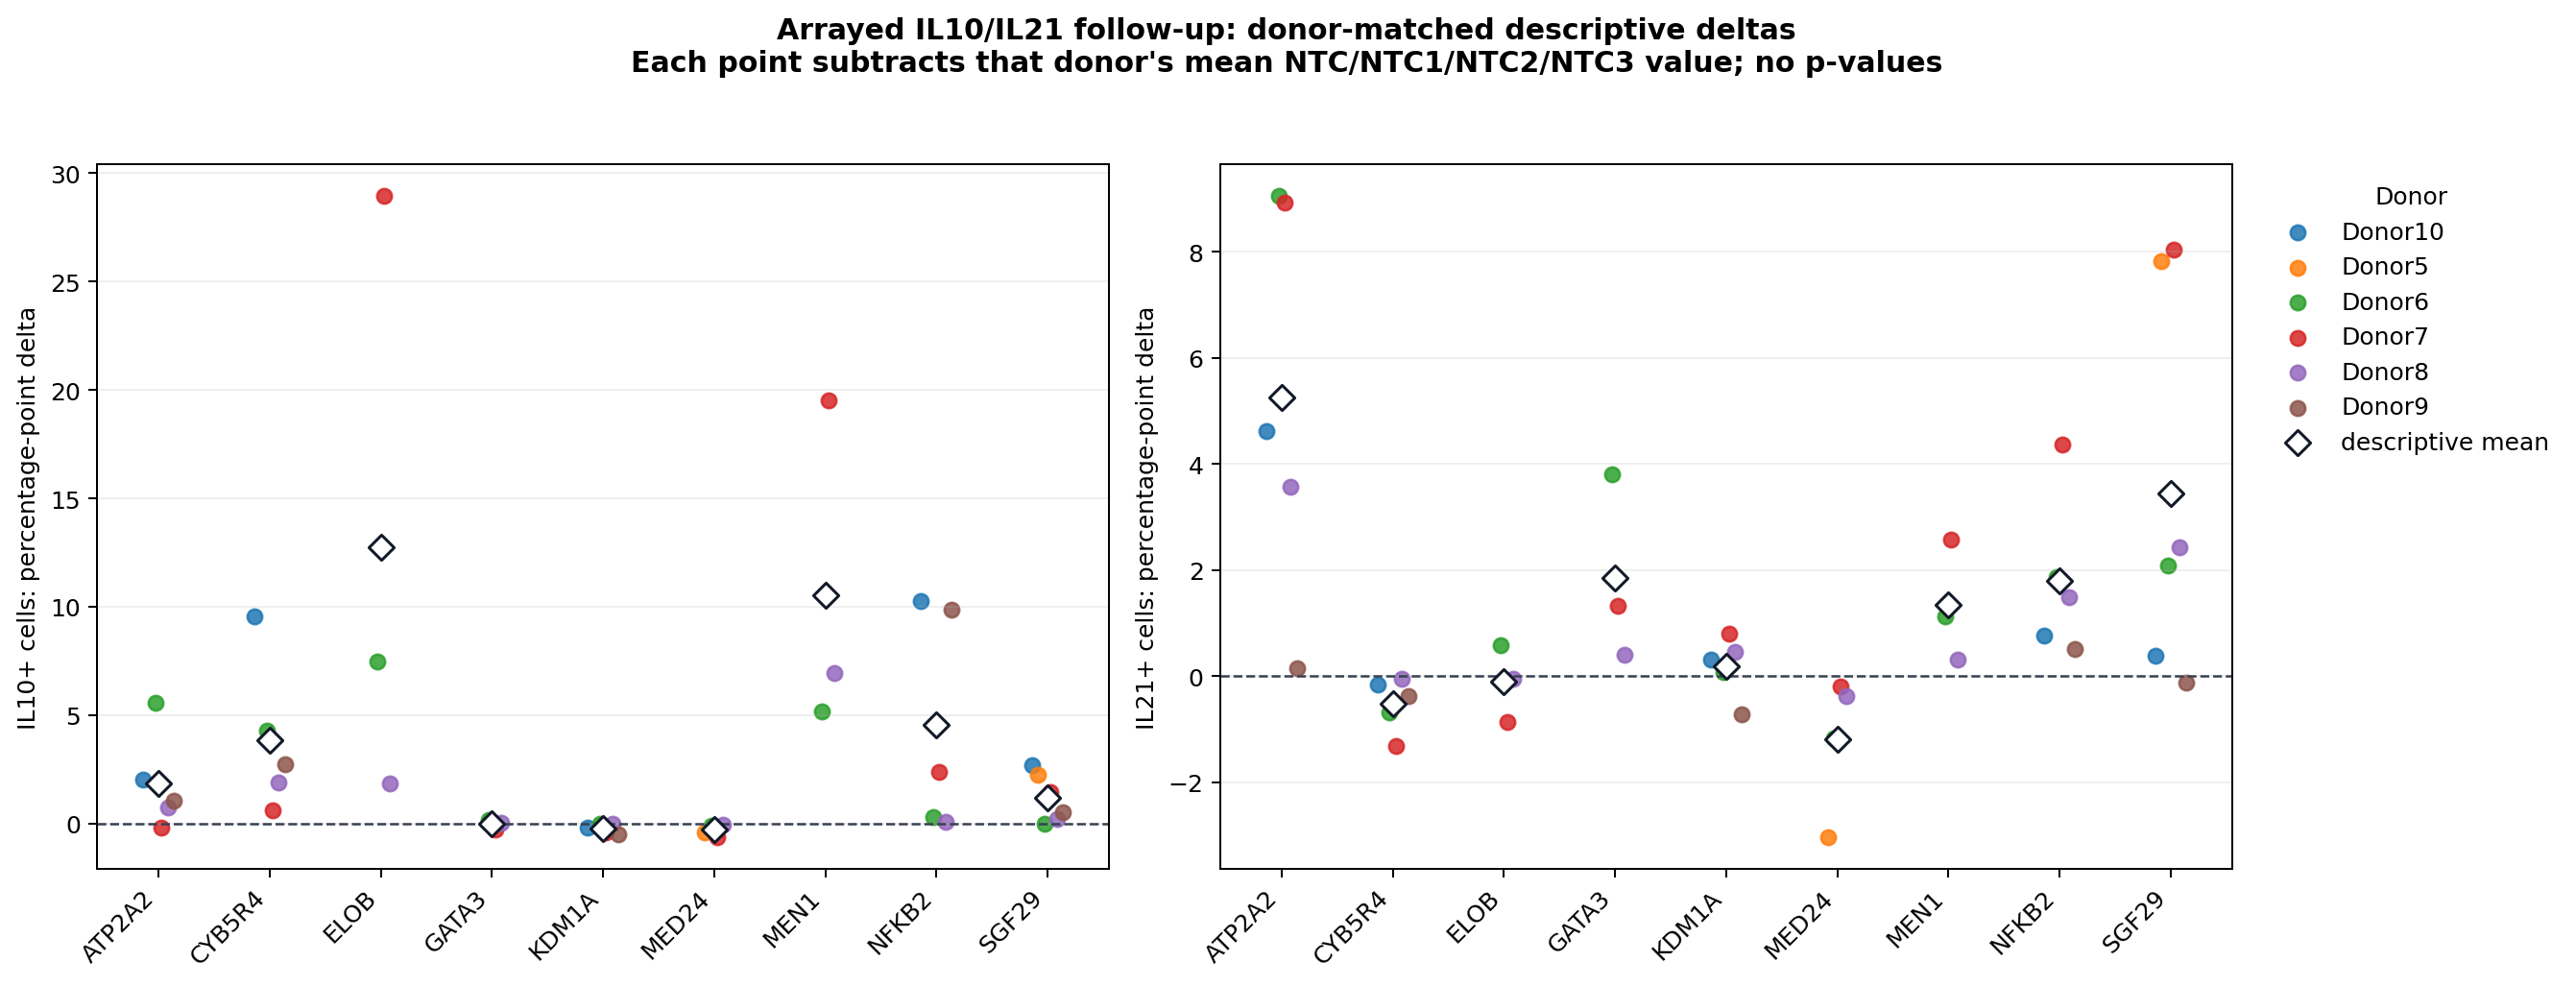

In [19]:
validation_summary = pd.read_csv(TABLE_DIR / "validation_summary.csv")
display(validation_summary)
display(Image(filename=FIGURE_DIR / "04_arrayed_validation_deltas.png", width=1000))


### Exercise 4 - Judge direction and consistency

For one perturbation, ask whether IL10 and IL21 deltas have the same sign in every donor. Then
separate three ideas: direction, magnitude, and uncertainty. A consistent descriptive direction
is encouraging, but the number of donors still limits precision.


In [20]:
# Answer scaffold: change this if you want to inspect another perturbation.
chosen_perturbation = donor_deltas["perturbation"].iloc[0]
chosen = donor_deltas.query("perturbation == @chosen_perturbation")
exercise_4 = {
    "perturbation": chosen_perturbation,
    "n_donors": chosen["donor"].nunique(),
    "all_positive_by_readout": {
        column: bool((chosen[column] > 0).all()) for column in delta_columns
    },
    "all_negative_by_readout": {
        column: bool((chosen[column] < 0).all()) for column in delta_columns
    },
    "uncertainty_statement": "TODO: explain why these descriptive deltas are not a p-value.",
}
exercise_4


{'perturbation': 'ATP2A2',
 'n_donors': 5,
 'all_positive_by_readout': {'IL10_delta_vs_donor_NTC': False,
  'IL21_delta_vs_donor_NTC': True},
 'all_negative_by_readout': {'IL10_delta_vs_donor_NTC': False,
  'IL21_delta_vs_donor_NTC': False},
 'uncertainty_statement': 'TODO: explain why these descriptive deltas are not a p-value.'}

## Step 10 - Read the generated report and methods

The report leads with the result and limitations. The methods record the exact filters and score
definition. Treat these as auditable outputs, not replacements for inspecting the tables above.


In [21]:
display(Markdown((OUTPUT_DIR / "report.md").read_text(encoding="utf-8")))


# Official CD4+ T-cell Perturb-seq Candidate Triage

## Answer first

**SETDB1** had the highest worst-condition priority score (0.915) among genes that passed source QC in Rest, Stim8hr, and Stim48hr. This is a descriptive prioritization result, not experimental verification.

The final source-QC pass counts were Rest: 497, Stim8hr: 593, Stim48hr: 562. A **source-QC pass** means a row met the declared
on-target, off-target, cell-count, cross-donor, and cross-guide gates. A **reproducible candidate**
means it passed those source gates in all three conditions. Neither label means wet-lab validated,
causal, safe, or therapeutically useful.

## Data actually used

This run used four small official supplementary CSVs from [https://github.com/emdann/GWT_perturbseq_analysis_2025](https://github.com/emdann/GWT_perturbseq_analysis_2025) at
commit `848d62fc2b7027f7218d6fc5f5b0c37255dc94af`. It did **not** download or analyze the 22-million-cell matrices. The
source audit passed for 12 screen samples and
4 screen donors across Rest, Stim8hr, and Stim48hr.

## Top candidates within each condition

| culture_condition   |   rank_within_condition | gene     |   n_downstream |   crossdonor_min |   crossguide |   priority_score |
|:--------------------|------------------------:|:---------|---------------:|-----------------:|-------------:|-----------------:|
| Rest                |                       1 | SETDB1   |           2290 |            0.735 |        0.909 |            0.945 |
| Rest                |                       2 | PTEN     |           2928 |            0.756 |        0.860 |            0.924 |
| Rest                |                       3 | ARNT     |           2319 |            0.752 |        0.842 |            0.912 |
| Rest                |                       4 | PAXIP1   |           1070 |            0.764 |        0.900 |            0.910 |
| Rest                |                       5 | EHMT2    |           1428 |            0.714 |        0.862 |            0.896 |
| Rest                |                       6 | NFRKB    |           3019 |            0.720 |        0.808 |            0.890 |
| Rest                |                       7 | THRAP3   |           1199 |            0.620 |        0.936 |            0.889 |
| Rest                |                       8 | AHR      |           2789 |            0.618 |        0.874 |            0.887 |
| Rest                |                       9 | MED12    |           2842 |            0.715 |        0.779 |            0.873 |
| Rest                |                      10 | TAF13    |           2189 |            0.623 |        0.832 |            0.866 |
| Rest                |                      11 | ELAVL1   |           2163 |            0.570 |        0.874 |            0.861 |
| Rest                |                      12 | USP22    |           1782 |            0.633 |        0.808 |            0.854 |
| Rest                |                      13 | CCND2    |           1286 |            0.647 |        0.814 |            0.852 |
| Rest                |                      14 | KDM1A    |           2017 |            0.629 |        0.799 |            0.851 |
| Rest                |                      15 | UFM1     |           1669 |            0.610 |        0.817 |            0.847 |
| Stim48hr            |                       1 | ARNT     |           2946 |            0.715 |        0.881 |            0.942 |
| Stim48hr            |                       2 | TADA2B   |           5259 |            0.648 |        0.870 |            0.921 |
| Stim48hr            |                       3 | SETDB1   |           1183 |            0.764 |        0.910 |            0.917 |
| Stim48hr            |                       4 | KDM1A    |           2912 |            0.718 |        0.813 |            0.913 |
| Stim48hr            |                       5 | ARHGAP30 |           1483 |            0.646 |        0.913 |            0.910 |
| Stim48hr            |                       6 | AHR      |           1821 |            0.736 |        0.834 |            0.909 |
| Stim48hr            |                       7 | GATA3    |           1252 |            0.705 |        0.884 |            0.906 |
| Stim48hr            |                       8 | CREBBP   |           1956 |            0.663 |        0.841 |            0.903 |
| Stim48hr            |                       9 | RASAL3   |            985 |            0.641 |        0.973 |            0.895 |
| Stim48hr            |                      10 | DOLPP1   |           1505 |            0.597 |        0.915 |            0.888 |
| Stim48hr            |                      11 | TMX1     |           1959 |            0.627 |        0.841 |            0.888 |
| Stim48hr            |                      12 | PCGF1    |           1078 |            0.768 |        0.853 |            0.887 |
| Stim48hr            |                      13 | NFRKB    |           2519 |            0.691 |        0.776 |            0.885 |
| Stim48hr            |                      14 | MIPEP    |           2143 |            0.626 |        0.826 |            0.883 |
| Stim48hr            |                      15 | TFAM     |           2960 |            0.682 |        0.772 |            0.883 |
| Stim8hr             |                       1 | ARNT     |           2642 |            0.695 |        0.864 |            0.916 |
| Stim8hr             |                       2 | SETDB1   |           1308 |            0.796 |        0.907 |            0.915 |
| Stim8hr             |                       3 | AHR      |           1776 |            0.686 |        0.890 |            0.905 |
| Stim8hr             |                       4 | PLCG1    |           5032 |            0.688 |        0.822 |            0.901 |
| Stim8hr             |                       5 | KDM1A    |           2300 |            0.692 |        0.844 |            0.900 |
| Stim8hr             |                       6 | NFRKB    |           2891 |            0.669 |        0.836 |            0.893 |
| Stim8hr             |                       7 | EHMT2    |           1177 |            0.765 |        0.853 |            0.885 |
| Stim8hr             |                       8 | BHLHE40  |           1996 |            0.731 |        0.796 |            0.880 |
| Stim8hr             |                       9 | CBLB     |           1027 |            0.665 |        0.920 |            0.877 |
| Stim8hr             |                      10 | TRIP12   |           1829 |            0.667 |        0.834 |            0.877 |
| Stim8hr             |                      11 | MED12    |           4141 |            0.687 |        0.776 |            0.876 |
| Stim8hr             |                      12 | DOLPP1   |           2717 |            0.595 |        0.859 |            0.875 |
| Stim8hr             |                      13 | WAC      |           2475 |            0.650 |        0.809 |            0.871 |
| Stim8hr             |                      14 | CD28     |           1505 |            0.626 |        0.857 |            0.864 |
| Stim8hr             |                      15 | TFAM     |            817 |            0.697 |        0.891 |            0.864 |

## Candidates passing all three conditions

|   cross_condition_rank | gene   |   Rest_priority_score |   Stim8hr_priority_score |   Stim48hr_priority_score |   min_priority_score | worst_condition   |
|-----------------------:|:-------|----------------------:|-------------------------:|--------------------------:|---------------------:|:------------------|
|                      1 | SETDB1 |                 0.945 |                    0.915 |                     0.917 |                0.915 | Stim8hr           |
|                      2 | ARNT   |                 0.912 |                    0.916 |                     0.942 |                0.912 | Rest              |
|                      3 | AHR    |                 0.887 |                    0.905 |                     0.909 |                0.887 | Rest              |
|                      4 | NFRKB  |                 0.890 |                    0.893 |                     0.885 |                0.885 | Stim48hr          |
|                      5 | EHMT2  |                 0.896 |                    0.885 |                     0.862 |                0.862 | Stim48hr          |
|                      6 | KDM1A  |                 0.851 |                    0.900 |                     0.913 |                0.851 | Rest              |
|                      7 | GATA3  |                 0.841 |                    0.840 |                     0.906 |                0.840 | Stim8hr           |
|                      8 | TFAM   |                 0.826 |                    0.864 |                     0.883 |                0.826 | Rest              |
|                      9 | TAF13  |                 0.866 |                    0.846 |                     0.823 |                0.823 | Stim48hr          |
|                     10 | PAXIP1 |                 0.910 |                    0.833 |                     0.822 |                0.822 | Stim48hr          |
|                     11 | TADA1  |                 0.831 |                    0.806 |                     0.834 |                0.806 | Stim8hr           |
|                     12 | SGF29  |                 0.806 |                    0.860 |                     0.868 |                0.806 | Rest              |

The cross-condition score is the minimum of the three condition-specific priority scores. This
conservative aggregation rewards a strong weakest condition, but it is **not** a formal
condition-by-perturbation interaction test. Differences between conditions are descriptive.

## Arrayed IL10/IL21 follow-up

| perturbation   |   n_donors |   IL10_mean_delta |   IL10_median_delta |   IL21_mean_delta |   IL21_median_delta |
|:---------------|-----------:|------------------:|--------------------:|------------------:|--------------------:|
| ELOB           |          3 |            12.755 |               7.471 |            -0.110 |              -0.043 |
| MEN1           |          3 |            10.551 |               6.934 |             1.340 |               1.123 |
| NFKB2          |          5 |             4.579 |               2.370 |             1.800 |               1.497 |
| CYB5R4         |          5 |             3.835 |               2.760 |            -0.516 |              -0.380 |
| ATP2A2         |          5 |             1.857 |               1.080 |             5.262 |               4.620 |
| SGF29          |          6 |             1.194 |               1.005 |             3.440 |               2.260 |
| GATA3          |          3 |            -0.019 |               0.024 |             1.847 |               1.330 |
| KDM1A          |          5 |            -0.211 |              -0.160 |             0.186 |               0.320 |
| MED24          |          4 |            -0.276 |              -0.235 |            -1.192 |              -0.770 |

Each delta subtracts the mean of that donor's available NTC, NTC1, NTC2, and NTC3 measurements.
Only descriptive donor-level summaries are shown; no inferential p-values were calculated. The
official source file calls this an arrayed validation experiment, but this report uses the more
limited term **arrayed follow-up** and does not turn a descriptive delta into a validation claim.

## How the priority score should be read

- `n_downstream` is the authors' number of downstream discoveries at 10% FDR. It is sensitive to
  statistical power and cell count and is **not an effect size**.
- `crossdonor_min` and `crossguide` are correlations reported by the source authors. This
  lightweight workflow filters and ranks them; it does not independently recompute them.
- Each metric is percentile-ranked within condition. Their geometric mean is a triage heuristic,
  not a calibrated probability of biological truth.
- The polarization coefficient table is retained only as an official descriptive annotation. It
  is not an extra independent validation layer.

## Deliverables

See `tables/` for all decisions and scores, `figures/` for the four teaching figures,
`methods.md` for the exact contract, and `provenance/manifest.json` for pinned URLs and hashes.


In [22]:
display(Markdown((OUTPUT_DIR / "methods.md").read_text(encoding="utf-8")))


# Methods — Official CD4+ T-cell Perturb-seq Lightweight Triage

## Source and scope

Four supplementary CSVs were downloaded from the authors' GitHub repository at immutable commit
`848d62fc2b7027f7218d6fc5f5b0c37255dc94af`. Expected byte sizes and SHA-256 hashes were checked before analysis. This
workflow uses published summary tables; it does not reprocess cell-level counts, rerun DESeq2, or
independently recompute cross-donor/cross-guide correlations.

## Blocking source audit

Required columns, numeric parsing, boolean parsing, unique perturbation-condition keys, unique
sample identifiers, presence of Rest/Stim8hr/Stim48hr, and a matched NTC-family control for every
arrayed donor were checked before scoring. A failed audit stops the run.

## Hard gates

A perturbation-condition row was labeled `source-QC pass` only when every criterion held:

1. `ontarget_significant == True` (the source authors' 10% FDR call),
2. `ontarget_effect_size < 0` (direction consistent with CRISPR interference knockdown),
3. `offtarget_flag == False`,
4. `n_cells_target >= 100`,
5. `crossdonor_correlation_min` was present and greater than zero, and
6. `crossguide_correlation` was present and greater than zero.

All pass/fail flags and failure reasons were retained in `tables/source_qc_decisions.csv`.

## Within-condition priority score

Among source-QC passes, `n_downstream`, `crossdonor_correlation_min`, and
`crossguide_correlation` were separately converted to average percentile ranks within each culture
condition using `rank(method="average", pct=True)`. The output columns are
`n_downstream_percentile`, `crossdonor_min_percentile`, and `crossguide_percentile`.

`priority_score = (n_downstream_percentile × crossdonor_min_percentile ×
crossguide_percentile)^(1/3)`

The geometric mean requires balanced performance: one weak component lowers the result. It does
not make the source metrics independent, and it is not a posterior probability or effect size.
`n_downstream` is the source authors' count of 10%-FDR downstream discoveries and depends on power
and cell count.

## Cross-condition ranking

Only genes with a source-QC pass in all three conditions were eligible. Their cross-condition
score was `min(Rest_priority_score, Stim8hr_priority_score, Stim48hr_priority_score)`. Genes were
ranked from largest to smallest minimum score. This is a descriptive robustness heuristic, not a
formal interaction analysis.

## Donor-matched arrayed follow-up

Within each donor, the mean IL10 and IL21 percentage among available perturbation labels exactly
matching NTC, NTC1, NTC2, or NTC3 was calculated. For each non-control sample:

`delta = observed percentage − donor mean NTC-family percentage`

Means, medians, minima, and maxima of these deltas were reported by perturbation. No p-values,
confidence intervals, or multiple-testing claims were produced because this small follow-up table
was used descriptively.

## Labels and inference boundary

`source-QC pass` and `reproducible candidate` are prioritization labels only. The workflow never
uses `verified` or `validated` as a computational conclusion. Experimental replication,
pre-specified endpoint testing, mechanism work, and safety evaluation remain outside scope.


## Common pitfalls

| Pitfall | Better interpretation or fix |
|---|---|
| Treating 22 million cells as 22 million independent experiments | The design has four donors; cells and guides are nested measurements. |
| Calling source-reported cross-donor/guide metrics independently reproduced | Say they were imported and audited from the authors' processed tables. |
| Calling `n_downstream` biological impact | It is the authors' 10% FDR discovery count and depends on power. |
| Scoring before quality gates | Apply eligibility gates first and preserve the failure ledger. |
| Calling a composite score a probability or p-value | It is a geometric mean of three within-condition percentile ranks. |
| Claiming context specificity from significant versus non-significant results | Fit a perturbation-by-condition interaction or direct contrast. |
| Pooling donor-matched deltas as independent technical replicates | Summarize by donor and report the small biological sample size. |
| Calling study-model coefficients independent validation | They are descriptive source annotations; this project does not refit them. |
| Calling IL10/IL21 follow-up target validation | Describe it as donor-matched, descriptive corroboration of selected readouts. |


## Extensions for a stronger project

1. **Independent cell-level recomputation:** download a tractable subset of the `.h5ad` files,
   rerun guide QC and donor-aware effect estimation, then compare with source-reported values.
2. **Prespecified component sensitivity:** before viewing results, define a leave-one-component-out
   check and report whether conclusions depend entirely on one source-reported metric.
3. **Formal condition interaction:** estimate perturbation-by-condition contrasts with donor and
   guide structure, then correct across tested interactions.
4. **Orthogonal validation:** confirm target knockdown and cytokine/state changes with an assay
   not used in the screen, ideally in new donors.
5. **Mechanistic follow-up:** test whether the candidate changes helper-T-cell polarization or
   function, not only IL10/IL21 abundance.


## Final teach-back

Explain this chain aloud without looking back:

> official processed tables -> source audit -> hard eligibility gates -> within-condition
> percentiles -> transparent geometric-mean rank -> descriptive cross-condition robustness ->
> descriptive polarization annotation -> donor-matched IL10/IL21 follow-up -> qualified claim
> and next experiment

Then answer:

1. Which metrics were independently recomputed, and which were source-reported?
2. Why is `n_downstream` power-dependent?
3. Why do hard filters precede the composite score?
4. Why is significant versus non-significant not an interaction test?
5. What would turn this target triage into stronger causal evidence?


In [23]:
# Final answer scaffold: fill this in using your own words.
teach_back = {
    "recomputed_here": [],
    "source_reported": [],
    "n_downstream_power_dependence": "",
    "hard_gates_before_ranking": "",
    "interaction_test_boundary": "",
    "next_causal_experiment": "",
}
teach_back


{'recomputed_here': [],
 'source_reported': [],
 'n_downstream_power_dependence': '',
 'hard_gates_before_ranking': '',
 'interaction_test_boundary': '',
 'next_causal_experiment': ''}